# Composition-dependent stability-limit curves

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import mpltex
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/plotting/paper_style.py').is_file()) / 'src/plotting'))
from paper_style import COLORS, configure_paper_style, style_axis, save_dual
configure_paper_style()
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'checkpoints/gnn').is_dir())
DATA=ROOT/'results/source_data/composition_curves'
OUT=ROOT/'results/figures/composition_curves'
df=pd.read_csv(DATA/'five_seed_phase_diagram_predictions.csv')
seed_columns=[f'seed_{s}' for s in range(202601,202606)]
np.testing.assert_allclose(df[seed_columns].mean(axis=1),df.ml_mean,rtol=1e-10)
np.testing.assert_allclose(df[seed_columns].std(axis=1,ddof=1),df.ml_std,rtol=1e-10)
assert df.groupby(['case','topology']).size().eq(100).all()
summary=[]
for (case,topology),g in df.groupby(['case','topology']):
    summary.append(dict(case=case,topology=topology,n=len(g),fA_min=g.fA.min(),fA_max=g.fA.max(),MAPE=np.mean(abs(g.ml_mean-g.rpa_chiN)/g.rpa_chiN)*100,coverage=np.mean(abs(g.ml_mean-g.rpa_chiN)<=g.ml_std)*100))
pd.DataFrame(summary).to_csv(DATA/'curve_metrics.csv',index=False)
print(pd.DataFrame(summary).to_string(index=False))
import json, math
from matplotlib.path import Path as MplPath
from matplotlib.patches import PathPatch
FIGURE_DIR = OUT / 'panel_sources'
FIGURE_DIR.mkdir(exist_ok=True)
def save(fig, name):
    save_dual(fig, FIGURE_DIR / name)
    fig.savefig((FIGURE_DIR / name).with_suffix('.pdf'), dpi=600, bbox_inches='tight',pad_inches=.03)
    plt.close(fig)


       case topology   n  fA_min  fA_max      MAPE  coverage
     btabat   BTABAT 100    0.01    0.99  6.774968      78.0
     global       AB 100    0.01    0.99  1.570886      74.0
     global      AB2 100    0.01    0.99  2.535326      92.0
     global      AB3 100    0.01    0.99  3.261537      84.0
     global      ABA 100    0.01    0.99  2.520045      78.0
     global     ABAB 100    0.01    0.99  3.619958      85.0
     global    ABABA 100    0.01    0.99  4.450728      79.0
     global   ABABAB 100    0.01    0.99  7.450349      71.0
     global       M1 100    0.01    0.99  4.974937      62.0
     global       M2 100    0.01    0.99  3.496411      83.0
m1_m2_local       M1 100    0.11    0.19  1.529381       0.0
m1_m2_local       M2 100    0.11    0.19  0.113750     100.0
        shi  (B2A2)2 100    0.01    0.99 12.446753      77.0
        shi       AB 100    0.01    0.99  1.570886      74.0
        shi     B2A2 100    0.01    0.99  3.203314      88.0


## Panels required for manuscript figures
Intermediate panels are saved for composition only; they are not displayed. Unused split-grid figures are not generated.

In [2]:
LEGEND_SIZE = 26

AXIS_LABEL_SIZE = 30

TICK_LABEL_SIZE = 24

ML_MARKER_SIZE = 11

TOPOLOGY_COLORS = {
    "AB": COLORS["blue"],
    "ABA": COLORS["orange"],
    "ABAB": COLORS["green"],
    "ABABA": COLORS["purple"],
    "AB2": COLORS["teal"],
    "AB3": COLORS["red"],
    "M1": COLORS["amber"],
    "M2": COLORS["teal"],
    "BTABAT": COLORS["density_green"],
    "B2A2": COLORS["mean_orange"],
    "(B2A2)2": COLORS["purple"],
}

LABELS = {
    "AB": r"$AB$", "ABA": r"$ABA$", "ABAB": r"$ABAB$", "ABABA": r"$ABABA$",
    "AB2": r"$AB_2$", "AB3": r"$AB_3$", "ABABAB": r"$ABABAB$",
    "M1": r"$M1$", "M2": r"$M2$",
    "BTABAT": r"$M_3$", "B2A2": r"$B_2A_2$", "(B2A2)2": r"$(B_2A_2)_2$",
}

def draw_series(
    ax, values: dict, topology: str, *, labeled: bool = True,
    marker_step: int = 4, color_override: str | None = None,
    band_alpha: float = 0.28,
) -> None:
    x = np.asarray(values["rpa"]["fA"])
    ml_x = np.asarray(values.get("ml_fA", values["rpa"]["fA"]))
    rpa = np.asarray(values["rpa"]["chiN"])
    mean = np.asarray(values["ml_mean"])
    std = np.asarray(values["ml_std"])
    band_x = np.asarray(values.get("band_fA", ml_x))
    band_mean = np.asarray(values.get("band_mean", mean))
    band_std = np.asarray(values.get("band_std", std))
    color = color_override or TOPOLOGY_COLORS[topology]
    prefix = f"{LABELS[topology]} " if labeled else ""
    ax.plot(x, rpa, color=color, lw=3.4, label=f"{prefix}RPA", zorder=2)
    ax.fill_between(band_x, np.maximum(band_mean - band_std, 0), band_mean + band_std,
                    color=color, alpha=band_alpha, linewidth=0, zorder=1)
    ax.plot(ml_x[::marker_step], mean[::marker_step], linestyle="none", marker="o", ms=ML_MARKER_SIZE,
            color=color, markeredgecolor="none", markeredgewidth=0,
            label=f"{prefix}GNN", zorder=3)

def structure_label_size(ax) -> float:
    """Scale topology labels to match M1's 32 pt on a 5.8-inch panel."""
    spec = ax.get_subplotspec()
    rows = spec.get_gridspec().nrows if spec is not None else 1
    panel_height = ax.figure.get_figheight() / rows
    return 32.0 * panel_height / 5.8

def add_standard_legend(ax) -> None:
    """Use one legend design and method ordering throughout the figure set."""
    handles, labels = ax.get_legend_handles_labels()
    # Matplotlib fills multi-column legends column-first.  Reorder the natural
    # topology-wise pairs so every visible row is ``RPA | GNN`` for the
    # same architecture.
    if len(handles) % 2 == 0:
        order = list(range(0, len(handles), 2)) + list(range(1, len(handles), 2))
        handles = [handles[index] for index in order]
        labels = [labels[index] for index in order]
    ax.legend(
        handles,
        labels,
        ncol=2,
        loc="upper center",
        fontsize=LEGEND_SIZE,
        frameon=False,
        handlelength=2.2,
        handletextpad=0.7,
        columnspacing=1.5,
        labelspacing=0.45,
        borderaxespad=0.55,
    )

def finish_axis(
    ax,
    *,
    xlim=(0, 1),
    ylim=(0, 210),
    annotation: str | None = None,
    annotation_x: float = 0.08,
    axis_label_size: float = AXIS_LABEL_SIZE,
    tick_label_size: float = TICK_LABEL_SIZE,
) -> None:
    ax.set(xlim=xlim, ylim=ylim, xlabel=r"$f_A$", ylabel=r"$\chi N$")
    if xlim == (0, 1):
        ax.set_xticks([0.1, 0.3, 0.5, 0.7, 0.9])
    if ylim == (0, 210):
        ax.set_yticks([0, 50, 100, 150, 200])
    elif ylim == (0, 550):
        ax.set_yticks([0, 100, 200, 300, 400, 500])
    if annotation:
        # The lower-left branch of every U-shaped spinodal contains data.  Keep
        # the panel identifier in the open upper-left region instead.
        ax.text(annotation_x, 0.78, annotation, transform=ax.transAxes,
                fontsize=structure_label_size(ax), fontstyle="italic")
    style_axis(ax)
    # Keep both coordinate directions visually identical in every panel.
    ax.xaxis.label.set_fontsize(axis_label_size)
    ax.yaxis.label.set_fontsize(axis_label_size)
    ax.tick_params(axis="both", which="major", labelsize=tick_label_size)

def plot_single(data: dict, topologies: list[str], name: str, *, figsize=(14, 10), ylim=(0, 210)) -> None:
    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    single_topology = len(topologies) == 1
    for topology in topologies:
        draw_series(ax, data[topology], topology, labeled=not single_topology)
    annotation = LABELS[topologies[0]] if single_topology else None
    finish_axis(ax, ylim=ylim, annotation=annotation,
                annotation_x=0.14 if single_topology else 0.08)
    add_standard_legend(ax)
    save(fig, name)

def plot_grid(data: dict, topologies: list[str], name: str, shape: tuple[int, int], *, ylim=(0, 550), figsize=(18, 11)) -> None:
    fig, axes = plt.subplots(*shape, figsize=figsize, constrained_layout=True, squeeze=False)
    for ax, topology in zip(axes.ravel(), topologies):
        draw_series(ax, data[topology], topology, labeled=False)
        finish_axis(ax, ylim=ylim, annotation=LABELS[topology])
        add_standard_legend(ax)
    for ax in axes.ravel()[len(topologies):]:
        ax.axis("off")
    save(fig, name)

def plot_ab_series(data: dict) -> None:
    """Combined AB/AB2/AB3 panel using the finalized global-panel style."""
    fig, ax = plt.subplots(figsize=(14, 10), constrained_layout=True)
    colors = {
        "AB": plt.rcParams["axes.labelcolor"],
        "AB2": COLORS["blue"],
        "AB3": COLORS["orange"],
    }
    legend_handles = []
    legend_labels = []
    for topology in ["AB", "AB2", "AB3"]:
        draw_series(
            ax, data[topology], topology, labeled=False,
            color_override=colors[topology], band_alpha=0.10,
        )
        handles, _ = ax.get_legend_handles_labels()
        legend_handles.extend([
            handles[-2],
            handles[-1],
            Patch(facecolor=colors[topology], alpha=0.10, edgecolor="none"),
        ])
        label = LABELS[topology]
        legend_labels.extend([
            f"{label} RPA calculate",
            f"{label} GNN predicate",
            f"{label} mean $\\pm$ 1 SD",
        ])

    finish_axis(
        ax, ylim=(0, 75),
        axis_label_size=32, tick_label_size=32,
    )
    ax.set_yticks([0, 25, 50, 75])
    ax.set_box_aspect(2 / 3)
    for topology, y_pos in zip(["AB", "AB2", "AB3"], [0.05, 0.12, 0.19]):
        ax.text(
            0.06, y_pos, LABELS[topology],
            transform=ax.transAxes, ha="left", va="bottom",
            fontsize=48, fontstyle="italic", color=colors[topology],
        )
    ax.legend(
        legend_handles[:3],
        ["RPA calculate", "GNN predicate", r"GNN mean $\pm$ 1 SD"],
        ncol=1,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.97),
        fontsize=28,
        frameon=False,
        handlelength=1.8,
        handletextpad=0.55,
        labelspacing=0.35,
        borderaxespad=0,
        alignment="center",
    )
    save(fig, "rpa_ab_series_publication")

def plot_shi_series(data: dict) -> None:
    """Combined Shi architecture series using the finalized AB-series style."""
    fig, ax = plt.subplots(figsize=(14, 10), constrained_layout=True)
    topologies = ["AB", "B2A2", "(B2A2)2"]
    colors = {
        "AB": plt.rcParams["axes.labelcolor"],
        "B2A2": COLORS["blue"],
        "(B2A2)2": COLORS["orange"],
    }
    method_handles = []
    for topology in topologies:
        draw_series(
            ax, data[topology], topology, labeled=False,
            color_override=colors[topology], band_alpha=0.10,
        )
        if not method_handles:
            handles, _ = ax.get_legend_handles_labels()
            method_handles = [
                handles[-2],
                handles[-1],
                Patch(facecolor=colors[topology], alpha=0.10, edgecolor="none"),
            ]

    finish_axis(
        ax, ylim=(0, 150),
        axis_label_size=32, tick_label_size=32,
    )
    ax.set_yticks([0, 50, 100, 150])
    ax.set_box_aspect(2 / 3)
    for topology, y_pos in zip(topologies, [0.19, 0.12, 0.05]):
        ax.text(
            0.06, y_pos, LABELS[topology],
            transform=ax.transAxes, ha="left", va="bottom",
            fontsize=48, fontstyle="italic", color=colors[topology],
        )
    ax.legend(
        method_handles,
        ["RPA calculate", "GNN predicate", r"GNN mean $\pm$ 1 SD"],
        ncol=1,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.97),
        fontsize=28,
        frameon=False,
        handlelength=1.8,
        handletextpad=0.55,
        labelspacing=0.35,
        borderaxespad=0,
        alignment="center",
    )
    save(fig, "shi_b2a2_series_publication")

def plot_architecture_series(data: dict) -> None:
    """Combined AB/ABAB/ABABAB panel using the finalized series style."""
    fig, ax = plt.subplots(figsize=(14, 10), constrained_layout=True)
    topologies = ["AB", "ABAB", "ABABAB"]
    colors = {
        "AB": plt.rcParams["axes.labelcolor"],
        "ABAB": COLORS["blue"],
        "ABABAB": COLORS["orange"],
    }
    method_handles = []
    for topology in topologies:
        draw_series(
            ax, data[topology], topology, labeled=False,
            color_override=colors[topology], band_alpha=0.10,
        )
        if not method_handles:
            handles, _ = ax.get_legend_handles_labels()
            method_handles = [
                handles[-2],
                handles[-1],
                Patch(facecolor=colors[topology], alpha=0.10, edgecolor="none"),
            ]

    finish_axis(
        ax, ylim=(0, 150),
        axis_label_size=32, tick_label_size=32,
    )
    ax.set_yticks([0, 50, 100, 150])
    ax.set_box_aspect(2 / 3)
    for topology, y_pos in zip(topologies, [0.19, 0.12, 0.05]):
        ax.text(
            0.005, y_pos, LABELS[topology],
            transform=ax.transAxes, ha="left", va="bottom",
            fontsize=48, fontstyle="italic", color=colors[topology],
            clip_on=False, in_layout=False,
        )
    ax.legend(
        method_handles,
        ["RPA calculate", "GNN predicate", r"GNN mean $\pm$ 1 SD"],
        ncol=1,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.97),
        fontsize=28,
        frameon=False,
        handlelength=1.8,
        handletextpad=0.55,
        labelspacing=0.35,
        borderaxespad=0,
        alignment="center",
    )
    save(fig, "rpa_ml_comparison_all_publication")

def plot_local_m1_m2(global_data: dict, local_data: dict) -> None:
    for topology in ["M1", "M2"]:
        fig, ax = plt.subplots(figsize=(12, 8), constrained_layout=True)
        values = global_data[topology]
        x = np.asarray(values["rpa"]["fA"])
        selected = (x >= 0.10) & (x <= 0.20)
        local_rpa = local_data[topology]["rpa"]
        local_rpa_x = np.asarray(local_rpa["fA"], dtype=float)
        local_rpa_y = np.asarray(local_rpa["chiN"], dtype=float)
        global_rpa_y = np.asarray(values["rpa"]["chiN"], dtype=float)
        global_rpa_mask = (x >= 0.08) & (x <= 0.22)
        rpa_x = np.concatenate([x[global_rpa_mask], local_rpa_x])
        rpa_y = np.concatenate([global_rpa_y[global_rpa_mask], local_rpa_y])
        order = np.argsort(rpa_x)
        subset = {
            "rpa": {
                "fA": rpa_x[order].tolist(),
                "chiN": rpa_y[order].tolist(),
            },
            "ml_fA": x[selected].tolist(),
            "ml_mean": np.asarray(values["ml_mean"])[selected].tolist(),
            "ml_std": np.asarray(values["ml_std"])[selected].tolist(),
            # Include adjacent already-inferred global compositions so the
            # uncertainty band reaches both visible x boundaries continuously.
            "band_fA": x[global_rpa_mask].tolist(),
            "band_mean": np.asarray(values["ml_mean"])[global_rpa_mask].tolist(),
            "band_std": np.asarray(values["ml_std"])[global_rpa_mask].tolist(),
        }
        # Keep the dense analytical local RPA line, while GNN points come only
        # from the already inferred global grid.
        draw_series(ax, subset, topology, labeled=False, marker_step=1,
                    color_override=plt.rcParams["axes.labelcolor"],
                    band_alpha=0.10)
        finish_axis(
            ax, xlim=(0.10, 0.20), ylim=(45, 175),
            axis_label_size=32, tick_label_size=32,
        )
        ax.set_box_aspect(2 / 3)
        ax.set_xticks([0.10, 0.12, 0.14, 0.16, 0.18, 0.20])
        ax.set_xticklabels(["0.10", "0.12", "0.14", "0.16", "0.18", "0.20"])
        ax.set_yticks([50, 75, 100, 125, 150, 175])
        ax.text(
            0.08, 0.10, LABELS[topology],
            transform=ax.transAxes, ha="left", va="bottom",
            fontsize=48, fontstyle="italic", color="#3568F4",
        )
        handles, labels = ax.get_legend_handles_labels()
        handles.append(Patch(facecolor=plt.rcParams["axes.labelcolor"], alpha=0.10,
                             edgecolor="none"))
        labels = ["RPA calculate", "GNN predicate", r"GNN mean $\pm$ 1 SD"]
        ax.legend(
            handles,
            labels,
            ncol=1,
            loc="upper right",
            bbox_to_anchor=(0.96, 0.96),
            fontsize=28,
            frameon=False,
            handlelength=2.2,
            handletextpad=0.7,
            labelspacing=0.45,
            borderaxespad=0,
            alignment="center",
        )
        save(fig, f"{topology.lower()}_comparison_publication")

def plot_btabat_local(data: dict) -> None:
    values = data["BTABAT"]
    x = np.asarray(values["rpa"]["fA"])
    marker_mask = (x > 0.10) & (x < 0.30)
    left = max(int(np.searchsorted(x, 0.10, side="left")) - 1, 0)
    right = min(int(np.searchsorted(x, 0.30, side="right")) + 1, len(x))
    continuous = slice(left, right)
    subset = {
        "rpa": {
            "fA": x[continuous].tolist(),
            "chiN": np.asarray(values["rpa"]["chiN"])[continuous].tolist(),
        },
        "ml_fA": x[marker_mask].tolist(),
        "ml_mean": np.asarray(values["ml_mean"])[marker_mask].tolist(),
        "ml_std": np.asarray(values["ml_std"])[marker_mask].tolist(),
        "band_fA": x[continuous].tolist(),
        "band_mean": np.asarray(values["ml_mean"])[continuous].tolist(),
        "band_std": np.asarray(values["ml_std"])[continuous].tolist(),
    }
    fig, ax = plt.subplots(figsize=(12, 8.5), constrained_layout=True)
    # The local window contains exactly 20 inferred compositions; show every
    # GNN prediction rather than applying the global marker thinning.
    draw_series(ax, subset, "BTABAT", labeled=False, marker_step=1,
                color_override=plt.rcParams["axes.labelcolor"], band_alpha=0.10)
    finish_axis(ax, xlim=(0.10, 0.30), ylim=(22, 175),
                axis_label_size=32, tick_label_size=32)
    ax.set_xticks([0.10, 0.15, 0.20, 0.25, 0.30])
    ax.set_xticklabels(["0.10", "0.15", "0.20", "0.25", "0.30"])
    ax.margins(x=0)
    ax.set_xlim(0.10, 0.30)
    # Use the requested plotting-window width:height ratio of 3:2.
    ax.set_box_aspect(2 / 3)
    ax.set_yticks([25, 50, 75, 100, 125, 150, 175])
    ax.text(
        0.08, 0.10, LABELS["BTABAT"],
        transform=ax.transAxes, ha="left", va="bottom",
        fontsize=48, fontstyle="italic", color="#3568F4",
    )
    handles, labels = ax.get_legend_handles_labels()
    handles.append(Patch(facecolor=plt.rcParams["axes.labelcolor"], alpha=0.10,
                         edgecolor="none"))
    labels = ["RPA calculate", "GNN predicate", r"GNN mean $\pm$ 1 SD"]
    ax.legend(
        handles,
        labels,
        ncol=1,
        loc="upper right",
        bbox_to_anchor=(0.96, 0.96),
        fontsize=28,
        frameon=False,
        handlelength=2.2,
        handletextpad=0.7,
        labelspacing=0.45,
        borderaxespad=0,
        alignment="center",
    )
    save(fig, "btabat_spinodal_local_publication")

def plot_btabat_global(data: dict) -> None:
    """BTABAT full-range panel matched proportionally to its local panel."""
    fig, ax = plt.subplots(figsize=(14, 10), constrained_layout=True)
    draw_series(ax, data["BTABAT"], "BTABAT", labeled=False,
                color_override=plt.rcParams["axes.labelcolor"], band_alpha=0.10)

    finish_axis(
        ax,
        ylim=(0, 200),
        axis_label_size=32,
        tick_label_size=32,
    )
    ax.set_yticks([0, 50, 100, 150, 200])
    ax.set_box_aspect(2 / 3)

    # Architecture label follows the local-panel placement.
    ax.text(
        0.08, 0.08, LABELS["BTABAT"], transform=ax.transAxes,
        ha="left", va="bottom", fontsize=48,
        fontstyle="italic", color="#3568F4",
    )
    handles, labels = ax.get_legend_handles_labels()
    handles.append(Patch(facecolor=plt.rcParams["axes.labelcolor"], alpha=0.10,
                         edgecolor="none"))
    labels = ["RPA calculate", "GNN predicate", r"GNN mean $\pm$ 1 SD"]
    ax.legend(
        handles,
        labels,
        ncol=1,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.96),
        fontsize=28,
        frameon=False,
        handlelength=2.2,
        handletextpad=0.7,
        labelspacing=0.45,
        borderaxespad=0,
        alignment="center",
    )
    save(fig, "btabat_spinodal_publication")

def plot_m1_m2_global(data: dict) -> None:
    """Save M1 and M2 as separate full-range BTABAT-style panels."""
    for topology in ["M1", "M2"]:
        fig, ax = plt.subplots(figsize=(14, 10), constrained_layout=True)
        draw_series(ax, data[topology], topology, labeled=False,
                    color_override=plt.rcParams["axes.labelcolor"],
                    band_alpha=0.10)
        finish_axis(
            ax, ylim=(0, 200),
            axis_label_size=32, tick_label_size=32,
        )
        ax.set_yticks([0, 50, 100, 150, 200])
        ax.set_box_aspect(2 / 3)
        ax.text(
            0.08, 0.08, LABELS[topology], transform=ax.transAxes,
            ha="left", va="bottom", fontsize=48,
            fontstyle="italic", color="#3568F4",
        )
        handles, labels = ax.get_legend_handles_labels()
        handles.append(Patch(facecolor=plt.rcParams["axes.labelcolor"], alpha=0.10,
                             edgecolor="none"))
        labels = ["RPA calculate", "GNN predicate", r"GNN mean $\pm$ 1 SD"]
        ax.legend(
            handles,
            labels,
            ncol=1,
            loc="upper center",
            bbox_to_anchor=(0.5, 0.96),
            fontsize=28,
            frameon=False,
            handlelength=2.2,
            handletextpad=0.7,
            labelspacing=0.45,
            borderaxespad=0,
            alignment="center",
        )
        save(fig, f"{topology.lower()}_global_publication")

def make_figures(data: dict) -> None:
    configure_paper_style()
    plot_architecture_series(data["global"])
    plot_ab_series(data["global"])
    plot_local_m1_m2(data["global"], data["m1_m2_local"])
    plot_m1_m2_global(data["global"])
    plot_btabat_global(data["btabat"])
    plot_btabat_local(data["btabat"])
    plot_shi_series(data["shi"])

payload=json.loads((DATA/"five_seed_phase_diagram_predictions.json").read_text())
make_figures(payload["cases"])


## Architecture drawing

In [3]:
A_COLOR = "#1248ff"

B_COLOR = "#ff7600"

NODE_COLOR = "#ad5100"

LINE_WIDTH = 5.8

NODE_SIZE = 46

LABEL_SIZE = 23

LEGEND_SIZE = 27

TITLE_SIZE = 25

DRAW_SEGMENT_LABELS = False

M1_FORMULA = r"$\mathrm{M}_1:\mathrm{A}_1(\mathrm{B}_1)\mathrm{T}(\mathrm{B}_3)\mathrm{T}\mathrm{B}_2\mathrm{A}_2$"

M2_FORMULA = r"$\mathrm{M}_2:\mathrm{A}_1(\mathrm{B}_3)\mathrm{T}\mathrm{B}_2\mathrm{A}_2$"

BTABAT_FORMULA = r"$\mathrm{A}_1(\mathrm{B}_1)_{\mathrm{T}}\mathrm{B}_2\mathrm{A}_2(\mathrm{A}_3)_{\mathrm{T}}\mathrm{B}_3$"

BTABAT_FULL_FORMULA = (
    r"$\mathrm{M}_3:"
    r"\mathrm{A}_1(\mathrm{B}_1)_{\mathrm{T}}\mathrm{B}_2\mathrm{A}_2"
    r"(\mathrm{A}_3)_{\mathrm{T}}\mathrm{B}_3$"
)

def bezier(ax, p0, p1, p2, p3, color, label=None, label_t=0.5, label_offset=(0, 0), rotation=None):
    path = MplPath([p0, p1, p2, p3], [MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4])
    patch = PathPatch(path, facecolor="none", edgecolor=color, lw=LINE_WIDTH, capstyle="round", joinstyle="round")
    ax.add_patch(patch)
    if not DRAW_SEGMENT_LABELS:
        return
    if label:
        x, y = cubic_point(p0, p1, p2, p3, label_t)
        if rotation is None:
            dx, dy = cubic_tangent(p0, p1, p2, p3, label_t)
            rotation = math.degrees(math.atan2(dy, dx))
        ax.text(
            x + label_offset[0],
            y + label_offset[1],
            label,
            color=color,
            fontsize=LABEL_SIZE,
            ha="center",
            va="center",
            rotation=rotation,
            rotation_mode="anchor",
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.72, "pad": 0.4},
        )

def cubic_point(p0, p1, p2, p3, t):
    u = 1 - t
    x = u**3 * p0[0] + 3 * u**2 * t * p1[0] + 3 * u * t**2 * p2[0] + t**3 * p3[0]
    y = u**3 * p0[1] + 3 * u**2 * t * p1[1] + 3 * u * t**2 * p2[1] + t**3 * p3[1]
    return x, y

def cubic_tangent(p0, p1, p2, p3, t):
    u = 1 - t
    dx = 3 * u**2 * (p1[0] - p0[0]) + 6 * u * t * (p2[0] - p1[0]) + 3 * t**2 * (p3[0] - p2[0])
    dy = 3 * u**2 * (p1[1] - p0[1]) + 6 * u * t * (p2[1] - p1[1]) + 3 * t**2 * (p3[1] - p2[1])
    return dx, dy

def setup_figure():
    fig, ax = plt.subplots(figsize=(7.0, 5.2), dpi=222)
    ax.set_aspect("equal")
    ax.axis("off")
    return fig, ax

def setup_axis(ax):
    ax.set_aspect("equal")
    ax.axis("off")

def add_block_legend(
    ax, *, loc="lower center", bbox_to_anchor=(0.5, -0.18), ncols=2,
    fontsize=LEGEND_SIZE,
):
    handles = [
        Line2D([0], [0], color=A_COLOR, lw=LINE_WIDTH, label="A block"),
        Line2D([0], [0], color=B_COLOR, lw=LINE_WIDTH, label="B block"),
    ]
    ax.legend(
        handles=handles,
        loc=loc,
        bbox_to_anchor=bbox_to_anchor,
        ncols=ncols,
        frameon=False,
        fontsize=fontsize,
        handlelength=2.4,
        columnspacing=3.0,
        handletextpad=0.8,
    )

def finish(fig, ax, path, include_legend=False, legend_kwargs=None):
    if include_legend:
        add_block_legend(ax, **(legend_kwargs or {}))
    ax.margins(0.10)
    fig.savefig(path, dpi=222, transparent=False, facecolor="white", bbox_inches="tight", pad_inches=0.15)
    fig.savefig(path.with_suffix(".svg"), transparent=False, facecolor="white",
                bbox_inches="tight", pad_inches=0.15)
    plt.close(fig)
    print(f"Saved {path}")

def nodes(ax, pts):
    xs = [p[0] for p in pts]
    ys = [p[1] for p in pts]
    ax.scatter(xs, ys, s=NODE_SIZE, color=NODE_COLOR, zorder=5, edgecolors="none")

def architecture_title(ax, text, fontsize=TITLE_SIZE):
    ax.text(
        0.5,
        1.03,
        text,
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=fontsize,
        fontfamily="STIXGeneral",
        color="black",
    )

def figure_title(fig, x, y, text):
    fig.text(
        x,
        y,
        text,
        ha="left",
        va="top",
        fontsize=TITLE_SIZE,
        fontfamily="STIXGeneral",
        color="black",
    )

def draw_m1_architecture(ax, *, show_nodes=True):
    c = (0.0, 0.0)
    b1_end = (-0.26, 0.43)
    b2_end = (1.18, 0.66)
    b3_end = (-1.34, 0.86)
    a2_end = (1.78, 1.05)
    a1_end = (-0.04, -0.76)

    bezier(ax, c, (-0.44, 0.18), (-0.88, 0.52), b3_end, B_COLOR, "B3", 0.55, (0.00, 0.12), -23)
    bezier(ax, c, (-0.08, 0.14), (-0.17, 0.29), b1_end, B_COLOR, "B1", 0.53, (-0.12, 0.04), -60)
    bezier(ax, c, (0.34, 0.21), (0.78, 0.44), b2_end, B_COLOR, "B2", 0.58, (0.02, 0.13), 38)
    bezier(ax, b2_end, (1.40, 0.80), (1.60, 0.94), a2_end, A_COLOR, "A2", 0.50, (0.00, 0.13), 25)
    bezier(ax, c, (0.05, -0.22), (0.04, -0.54), a1_end, A_COLOR, "A1", 0.55, (0.13, 0.00), 83)
    if show_nodes:
        nodes(ax, [c, b1_end, b2_end, b3_end, a2_end, a1_end])

def draw_m1(path: Path):
    fig, ax = setup_figure()
    architecture_title(ax, M1_FORMULA)
    draw_m1_architecture(ax)
    finish(fig, ax, path, include_legend=True)

def draw_m2_architecture(ax, *, show_nodes=True):
    c = (0.0, 0.0)
    b1_end = (-0.95, 0.38)
    b2_end = (0.95, 0.42)
    a2_end = (1.55, 0.88)
    a1_end = (-0.02, -1.00)

    bezier(ax, c, (-0.25, 0.05), (-0.58, 0.22), b1_end, B_COLOR, "B1", 0.50, (-0.02, 0.11), -25)
    bezier(ax, c, (0.28, 0.10), (0.62, 0.25), b2_end, B_COLOR, "B2", 0.54, (0.02, 0.13), 28)
    bezier(ax, b2_end, (1.16, 0.58), (1.38, 0.76), a2_end, A_COLOR, "A2", 0.54, (0.00, 0.13), 32)
    bezier(ax, c, (0.06, -0.30), (0.04, -0.70), a1_end, A_COLOR, "A1", 0.55, (0.13, 0.00), 86)
    if show_nodes:
        nodes(ax, [c, b1_end, b2_end, a2_end, a1_end])

def draw_m2(path: Path):
    fig, ax = setup_figure()
    architecture_title(ax, M2_FORMULA)
    draw_m2_architecture(ax)
    finish(fig, ax, path, include_legend=True)

def draw_m1_m2(path: Path):
    fig, axes = plt.subplots(1, 2, figsize=(12.6, 5.2), dpi=222)
    for ax in axes:
        setup_axis(ax)
    architecture_title(axes[0], M1_FORMULA)
    architecture_title(axes[1], M2_FORMULA)
    draw_m1_architecture(axes[0])
    draw_m2_architecture(axes[1])
    handles = [
        Line2D([0], [0], color=A_COLOR, lw=LINE_WIDTH, label="A block"),
        Line2D([0], [0], color=B_COLOR, lw=LINE_WIDTH, label="B block"),
    ]
    fig.legend(
        handles=handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.00),
        ncols=2,
        frameon=False,
        fontsize=LEGEND_SIZE,
        handlelength=2.4,
        columnspacing=3.0,
        handletextpad=0.8,
    )
    fig.subplots_adjust(left=0.02, right=0.98, top=0.96, bottom=0.23, wspace=0.08)
    fig.savefig(path, dpi=222, transparent=False, facecolor="white", bbox_inches="tight", pad_inches=0.15)
    plt.close(fig)
    print(f"Saved {path}")

def draw_btabat_architecture(ax):
    t_a = (-0.58, 0.40)
    ab = (0.00, 0.05)
    t_b = (0.48, -0.28)
    a1_end = (0.58, -0.92)
    a3_end = (-0.60, 1.30)
    b2_end = (-1.30, 0.22)
    b3_end = (1.85, -0.10)

    bezier(ax, t_b, (0.50, -0.50), (0.54, -0.75), a1_end, A_COLOR, "A1", 0.58, (0.13, 0.00), 82)
    bezier(ax, t_b, (0.28, -0.14), (0.12, -0.02), ab, A_COLOR, "A2", 0.54, (-0.08, -0.11), -54)
    bezier(ax, ab, (-0.16, 0.16), (-0.35, 0.30), t_a, B_COLOR, "B1", 0.54, (0.07, 0.10), 41)
    bezier(ax, t_a, (-0.86, 0.30), (-1.08, 0.22), b2_end, B_COLOR, "B2", 0.54, (0.00, 0.12), 12)
    bezier(ax, t_a, (-0.66, 0.70), (-0.70, 1.06), a3_end, A_COLOR, "A3", 0.50, (-0.13, 0.00), 87)
    bezier(ax, t_b, (0.88, -0.18), (1.34, -0.08), b3_end, B_COLOR, "B3", 0.56, (0.00, 0.13), 6)

def draw_btabat(path: Path):
    fig, ax = setup_figure()
    architecture_title(ax, BTABAT_FORMULA, fontsize=36)
    draw_btabat_architecture(ax)
    finish(
        fig, ax, path, include_legend=True,
        legend_kwargs={
            "loc": "upper right", "bbox_to_anchor": (0.98, 0.93),
            "ncols": 1, "fontsize": 20,
        },
    )

def draw_m1_m2_btabat(path: Path):
    """Draw the three node-free architectures with one legend at far right."""
    fig, axes = plt.subplots(1, 3, figsize=(27.0, 6.5), dpi=222)
    for ax in axes:
        setup_axis(ax)

    draw_m1_architecture(axes[0], show_nodes=False)
    draw_m2_architecture(axes[1], show_nodes=False)
    draw_btabat_architecture(axes[2])
    for ax in axes:
        ax.margins(0.10)

    handles = [
        Line2D([0], [0], color=A_COLOR, lw=LINE_WIDTH, label="A block"),
        Line2D([0], [0], color=B_COLOR, lw=LINE_WIDTH, label="B block"),
    ]
    fig.legend(
        handles=handles, loc="center right", bbox_to_anchor=(0.995, 0.55),
        ncols=1, frameon=False, fontsize=20, handlelength=2.4,
        handletextpad=0.8, labelspacing=0.7,
    )
    fig.subplots_adjust(left=0.015, right=0.86, top=0.82, bottom=0.07, wspace=0.12)
    panel_width = (0.86 - 0.015) / 3.0
    title_centers = [0.015 + panel_width * (index + 0.5) for index in range(3)]
    for center, title in zip(title_centers, [M1_FORMULA, M2_FORMULA, BTABAT_FULL_FORMULA]):
        fig.text(
            center, 0.92, title, ha="center", va="center",
            fontsize=36, fontfamily="STIXGeneral", color="black",
        )
    save_dual(fig, path.with_suffix(""))
    fig.savefig(path.with_suffix(".pdf"), dpi=600, bbox_inches="tight", pad_inches=.03)
    plt.close(fig)
    print(f"Saved {path}")

def draw_legend(path: Path):
    fig, ax = plt.subplots(figsize=(6.0, 0.9), dpi=222)
    ax.axis("off")
    handles = [
        Line2D([0], [0], color=A_COLOR, lw=LINE_WIDTH, label="A block"),
        Line2D([0], [0], color=B_COLOR, lw=LINE_WIDTH, label="B block"),
    ]
    ax.legend(
        handles=handles,
        loc="center",
        ncols=2,
        frameon=False,
        fontsize=LEGEND_SIZE,
        handlelength=2.4,
        columnspacing=3.0,
        handletextpad=0.8,
    )
    fig.savefig(path, dpi=222, facecolor="white", bbox_inches="tight", pad_inches=0.1)
    plt.close(fig)
    print(f"Saved {path}")
def draw_architecture_inset(drawer, path: Path):
    """Save one node-free architecture for aligned dashboard composition."""
    fig, ax = plt.subplots(figsize=(7.0, 4.2), dpi=222)
    setup_axis(ax)
    if drawer is draw_btabat_architecture:
        drawer(ax)
    else:
        drawer(ax, show_nodes=False)
    ax.margins(0.10)
    save_dual(fig, path.with_suffix(""))
    fig.savefig(path.with_suffix(".pdf"), dpi=600, bbox_inches="tight", pad_inches=.03)
    plt.close(fig)

configure_paper_style()
draw_architecture_inset(draw_m1_architecture, FIGURE_DIR/"m1_structure_inset.png")
draw_architecture_inset(draw_m2_architecture, FIGURE_DIR/"m2_structure_inset.png")
draw_architecture_inset(draw_btabat_architecture, FIGURE_DIR/"m3_structure_inset.png")
draw_m1_m2_btabat(FIGURE_DIR/"M1_M2_BTABAT_structure.png")
display(Image(filename=str(FIGURE_DIR/"M1_M2_BTABAT_structure.png"),width=1200))


Saved D:\2026\paper\TAPD\sourcecode\code\results\figures\composition_curves\panel_sources\M1_M2_BTABAT_structure.png


## Manuscript dashboards

In [ ]:
# Final composition code (kept here as the single source of truth).
_composition_scripts = [
    ('experiments\\composition_curves\\compose_figure6.py', 'from pathlib import Path\n\nfrom PIL import Image, ImageDraw, ImageFont\n\n\nROOT = Path(__file__).resolve().parents[2] / "results/figures/composition_curves"\nINPUTS = [\n    ROOT / "rpa_ab_series_publication.png",\n    ROOT / "rpa_ml_comparison_all_publication.png",\n    ROOT / "shi_b2a2_series_publication.png",\n]\nOUTPUT = ROOT / "figure6_stability_limit_dashboard.png"\n\npanel_width, panel_height = 2400, 1677\nheader_height, gutter = 160, 24\npanels = []\n\nfor index, path in enumerate(INPUTS):\n    image = Image.open(path).convert("RGB")\n    if index < 2:\n        # ponytail: erase only the shared top legend; the right panel retains it.\n        ImageDraw.Draw(image).rectangle(\n            (int(image.width * 0.38), int(image.height * 0.03),\n             int(image.width * 0.74), int(image.height * 0.22)),\n            fill="white",\n        )\n    canvas = Image.new("RGB", (image.width, 5858), "white")\n    canvas.paste(image, (0, (5858 - image.height) // 2))\n    panels.append(canvas.resize((panel_width, panel_height), Image.Resampling.LANCZOS))\n\ndashboard = Image.new(\n    "RGB",\n    (panel_width * 3 + gutter * 2, header_height + panel_height),\n    "white",\n)\nfont = ImageFont.truetype(r"C:\\Windows\\Fonts\\times.ttf", 112)\ndraw = ImageDraw.Draw(dashboard)\nfor index, panel in enumerate(panels):\n    x = index * (panel_width + gutter)\n    draw.text((x + 24, 8), f"({chr(97 + index)})", fill="black", font=font)\n    dashboard.paste(panel, (x, header_height))\n\ndashboard.save(OUTPUT, dpi=(600, 600), optimize=True)\nassert dashboard.size == (7248, 1837)\nprint(OUTPUT)\n'),
    ('experiments\\composition_curves\\compose_figure7_dashboard.py', 'from base64 import b64encode\nfrom pathlib import Path\nimport re\n\nfrom PIL import Image, ImageDraw, ImageFont\n\n\nHERE = Path(__file__).resolve().parents[2] / "results/figures/composition_curves"\nPANELS = [\n    ("(a)", "m1_global_publication", 0, 0),\n    ("(b)", "m2_global_publication", 0, 1),\n    ("(c)", "btabat_spinodal_publication", 0, 2),\n    ("(d)", "m1_comparison_publication", 1, 0),\n    ("(e)", "m2_comparison_publication", 1, 1),\n    ("(f)", "btabat_spinodal_local_publication", 1, 2),\n]\n\n\ndef without_svg_legend(svg):\n    start = svg.find(\'<g id="legend_1">\')\n    if start < 0:\n        return svg\n    depth = 0\n    for match in re.finditer(r"<g\\b|</g>", svg[start:]):\n        depth += 1 if match.group() == "<g" else -1\n        if depth == 0:\n            return svg[:start] + svg[start + match.end():]\n    raise ValueError("Unclosed SVG legend group")\n\n\ndef main():\n    panel_w, panel_h, gap, label_h = 1540, 1120, 55, 80\n    width, height = panel_w * 3 + gap * 2, panel_h * 2\n    font = ImageFont.truetype(r"C:\\Windows\\Fonts\\arialbd.ttf", 72)\n    canvas = Image.new("RGB", (width, height), "white")\n    draw = ImageDraw.Draw(canvas)\n\n    svg_images = []\n    for label, stem, row, col in PANELS:\n        keep_legend = row == 0 and col == 2\n        x, cell_y = col * (panel_w + gap), row * panel_h\n        y = cell_y + label_h\n        image = Image.open(HERE / f"{stem}.png").convert("RGB")\n        if not keep_legend:\n            x0, x1 = ((0.34, 0.80) if row == 0 else (0.42, 0.935))\n            ImageDraw.Draw(image).rectangle(\n                (int(image.width * x0), int(image.height * 0.065),\n                 int(image.width * x1), int(image.height * 0.29)),\n                fill="white",\n            )\n        image.thumbnail((panel_w, panel_h - label_h), Image.Resampling.LANCZOS)\n        px, py = x + (panel_w - image.width) // 2, y + (panel_h - label_h - image.height) // 2\n        canvas.paste(image, (px, py))\n        draw.text((x + 10, cell_y + 2), label, fill="black", font=font)\n        source_svg = (HERE / f"{stem}.svg").read_text(encoding="utf-8")\n        if not keep_legend:\n            source_svg = without_svg_legend(source_svg)\n        encoded = b64encode(source_svg.encode()).decode("ascii")\n        svg_images.append(\n            f\'<image x="{x}" y="{y}" width="{panel_w}" height="{panel_h - label_h}" \'\n            f\'preserveAspectRatio="xMidYMid meet" href="data:image/svg+xml;base64,{encoded}"/>\'\n            f\'<text x="{x + 10}" y="{cell_y + 62}" font-family="Arial" font-size="72" \'\n            f\'font-weight="bold">{label}</text>\'\n        )\n\n    canvas.save(HERE / "figure7a_f_dashboard.png", dpi=(600, 600), optimize=True)\n    svg = (\n        f\'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" \'\n        f\'viewBox="0 0 {width} {height}"><rect width="100%" height="100%" fill="white"/>\'\n        + "".join(svg_images) + "</svg>"\n    )\n    (HERE / "figure7a_f_dashboard.svg").write_text(svg, encoding="utf-8")\n\n    assert canvas.size == (4730, 2240)\n    assert all(f">{label}</text>" in svg for label, *_ in PANELS)\n\n\nif __name__ == "__main__":\n    main()\n'),
    ('experiments\\composition_curves\\compose_figure8_literature.py', '# Academic Figure Skill Asset Confirmation (verified against existing manuscript panels)\n# (a-c) architecture schematics -> notebook-rendered single panels -> native composition\n# (d-i) stability-limit curves -> existing publication panels -> native composition\n# ponytail: this compositor only removes duplicated legends and adds panel labels;\n# the notebook remains the source of every plotted datum and curve.\nfrom base64 import b64encode\nfrom pathlib import Path\nimport re\n\nfrom PIL import Image, ImageDraw, ImageFont\n\n\nHERE = Path(__file__).resolve().parents[2] / "results/figures/composition_curves"\nSOURCE = HERE / "panel_sources" if (HERE / "panel_sources").is_dir() else HERE\nSTRUCTURES = [\n    ("(a)", "m1_structure_inset", "M1", 0),\n    ("(b)", "m2_structure_inset", "M2", 1),\n    ("(c)", "m3_structure_inset", "M3", 2),\n]\nCURVES = [\n    ("(d)", "m1_global_publication", 0, 0),\n    ("(e)", "m2_global_publication", 0, 1),\n    ("(f)", "btabat_spinodal_publication", 0, 2),\n    ("(g)", "m1_comparison_publication", 1, 0),\n    ("(h)", "m2_comparison_publication", 1, 1),\n    ("(i)", "btabat_spinodal_local_publication", 1, 2),\n]\n\n\ndef without_svg_legend(svg):\n    start = svg.find(\'<g id="legend_1">\')\n    if start < 0:\n        return svg\n    depth = 0\n    for match in re.finditer(r"<g\\b|</g>", svg[start:]):\n        depth += 1 if match.group() == "<g" else -1\n        if depth == 0:\n            return svg[:start] + svg[start + match.end():]\n    raise ValueError("Unclosed SVG legend group")\n\n\ndef embedded_svg(stem, x, y, width, height, keep_legend=True):\n    svg = (SOURCE / f"{stem}.svg").read_text(encoding="utf-8")\n    if not keep_legend:\n        svg = without_svg_legend(svg)\n    encoded = b64encode(svg.encode()).decode("ascii")\n    return (\n        f\'<image x="{x}" y="{y}" width="{width}" height="{height}" \'\n        f\'preserveAspectRatio="xMidYMid meet" \'\n        f\'href="data:image/svg+xml;base64,{encoded}"/>\'\n    )\n\n\ndef main():\n    panel_w, panel_h, gap, label_h = 1540, 1120, 55, 80\n    width = panel_w * 3 + gap * 2\n    legend_h, structure_h = 130, 850\n    height = legend_h + structure_h + panel_h * 2\n    font = ImageFont.truetype(r"C:\\Windows\\Fonts\\arialbd.ttf", 72)\n    legend_font = ImageFont.truetype(r"C:\\Windows\\Fonts\\arial.ttf", 52)\n    name_font = ImageFont.truetype(r"C:\\Windows\\Fonts\\ariali.ttf", 60)\n    canvas = Image.new("RGB", (width, height), "white")\n    draw = ImageDraw.Draw(canvas)\n\n    # One centered horizontal legend for all three architecture panels.\n    legend_y = 55\n    legend_items = [("#1248ff", "A block"), ("#ff7600", "B block")]\n    legend_x = width // 2 - 520\n    svg_images = []\n    for index, (color, text) in enumerate(legend_items):\n        x = legend_x + index * 560\n        draw.line((x, legend_y, x + 145, legend_y), fill=color, width=18)\n        draw.text((x + 180, legend_y - 31), text, fill="black", font=legend_font)\n        svg_images.append(\n            f\'<line x1="{x}" y1="{legend_y}" x2="{x + 145}" y2="{legend_y}" \'\n            f\'stroke="{color}" stroke-width="18" stroke-linecap="round"/>\'\n            f\'<text x="{x + 180}" y="{legend_y + 18}" font-family="Arial" \'\n            f\'font-size="52">{text}</text>\'\n        )\n\n    for label, stem, name, col in STRUCTURES:\n        x = col * (panel_w + gap)\n        cell_y = legend_h\n        y = cell_y + label_h\n        image = Image.open(SOURCE / f"{stem}.png").convert("RGB")\n        image.thumbnail((panel_w - 130, structure_h - label_h - 90), Image.Resampling.LANCZOS)\n        px = x + (panel_w - image.width) // 2\n        py = y + (structure_h - label_h - 90 - image.height) // 2\n        canvas.paste(image, (px, py))\n        draw.text((x + 10, cell_y + 2), label, fill="black", font=font)\n        name_box = draw.textbbox((0, 0), name, font=name_font)\n        draw.text((x + (panel_w - (name_box[2] - name_box[0])) // 2,\n                   cell_y + structure_h - 82), name, fill="black", font=name_font)\n        svg_images.append(\n            embedded_svg(stem, x + 65, y, panel_w - 130, structure_h - label_h - 90)\n        )\n        svg_images.append(\n            f\'<text x="{x + 10}" y="{cell_y + 62}" font-family="Arial" \'\n            f\'font-size="72" font-weight="bold">{label}</text>\'\n            f\'<text x="{x + panel_w / 2}" y="{cell_y + structure_h - 30}" \'\n            f\'font-family="Arial" font-size="60" font-style="italic" \'\n            f\'text-anchor="middle">{name}</text>\'\n        )\n\n    for label, stem, row, col in CURVES:\n        keep_legend = row == 0 and col == 2\n        x = col * (panel_w + gap)\n        cell_y = legend_h + structure_h + row * panel_h\n        y = cell_y + label_h\n        image = Image.open(SOURCE / f"{stem}.png").convert("RGB")\n        if not keep_legend:\n            x0, x1 = ((0.34, 0.80) if row == 0 else (0.42, 0.935))\n            ImageDraw.Draw(image).rectangle(\n                (int(image.width * x0), int(image.height * 0.065),\n                 int(image.width * x1), int(image.height * 0.29)),\n                fill="white",\n            )\n        image.thumbnail((panel_w, panel_h - label_h), Image.Resampling.LANCZOS)\n        px = x + (panel_w - image.width) // 2\n        py = y + (panel_h - label_h - image.height) // 2\n        canvas.paste(image, (px, py))\n        draw.text((x + 10, cell_y + 2), label, fill="black", font=font)\n        svg_images.append(\n            embedded_svg(stem, x, y, panel_w, panel_h - label_h, keep_legend)\n        )\n        svg_images.append(\n            f\'<text x="{x + 10}" y="{cell_y + 62}" font-family="Arial" \'\n            f\'font-size="72" font-weight="bold">{label}</text>\'\n        )\n\n    output = HERE / "figure8_literature_architectures_stability_limits"\n    canvas.save(output.with_suffix(".png"), dpi=(600, 600), optimize=True)\n    svg = (\n        f\'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" \'\n        f\'viewBox="0 0 {width} {height}"><rect width="100%" height="100%" fill="white"/>\'\n        + "".join(svg_images) + "</svg>"\n    )\n    output.with_suffix(".svg").write_text(svg, encoding="utf-8")\n\n    assert canvas.size == (4730, 3220)\n    assert all(f">({letter})</text>" in svg for letter in "abcdefghi")\n    print(output)\n\n\nif __name__ == "__main__":\n    main()\n'),

]
for relative_name, source in _composition_scripts:
    virtual_file = CODE / relative_name
    namespace = {"__file__": str(virtual_file), "__name__": "__main__"}
    exec(compile(source, str(virtual_file), "exec"), namespace)
    print("Completed:", relative_name)



## Candidate Fig. 10 layouts: error strips and local residuals


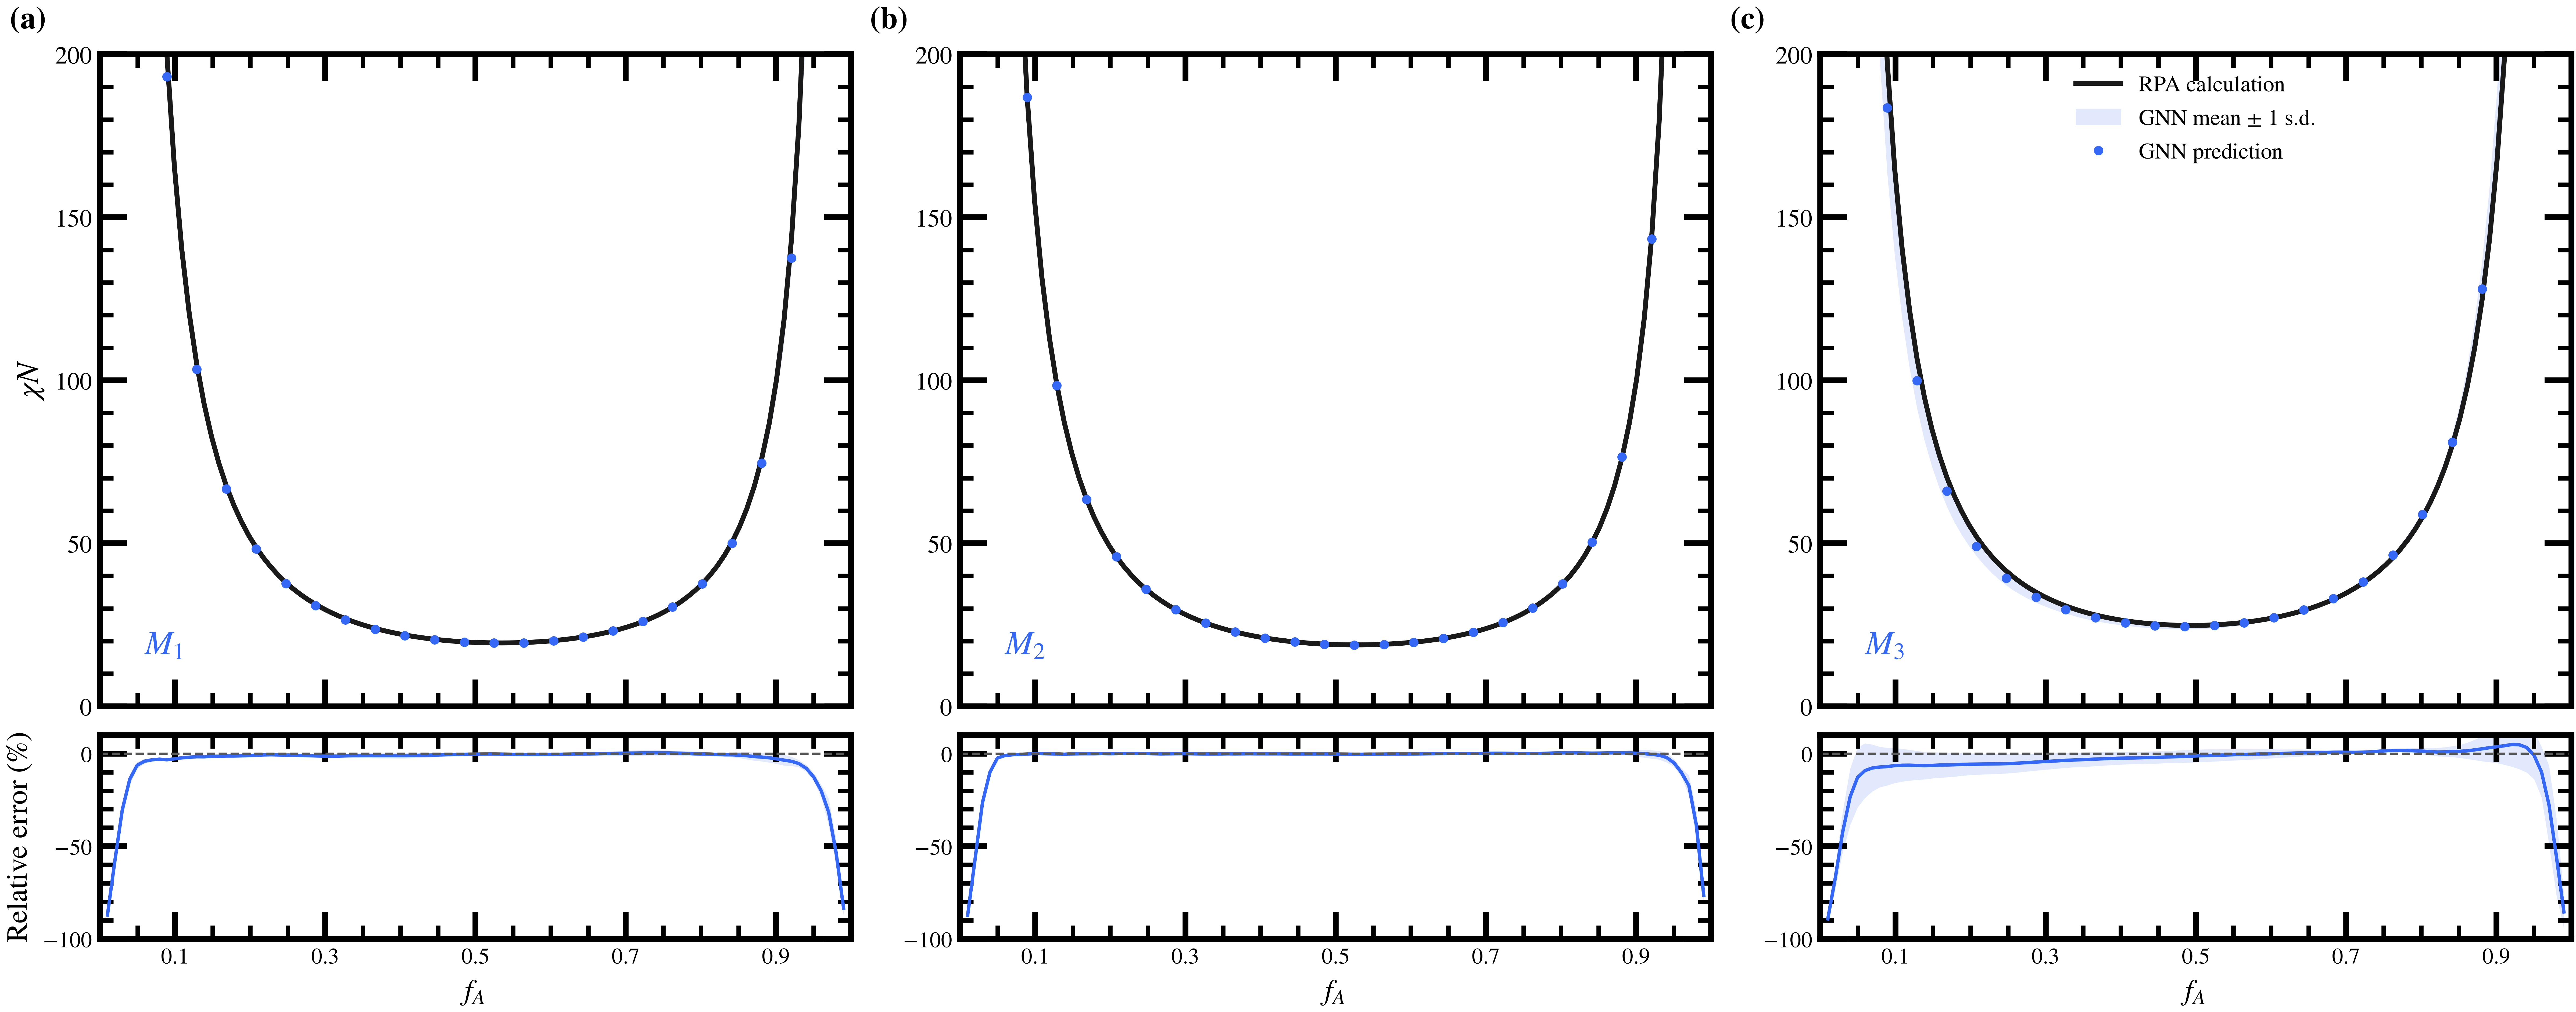

In [5]:
# Candidate A: global curves with narrow signed-relative-error strips.
# Candidate B: replace the local-zoom row with residuals in the literature windows.
CANDIDATE_TOPOLOGIES = [
    ("M1", "global", r"$M_1$", (0.10, 0.20)),
    ("M2", "global", r"$M_2$", (0.10, 0.20)),
    ("BTABAT", "btabat", r"$M_3$", (0.10, 0.30)),
]
RPA_COLOR = "#1A1A1A"
GNN_COLOR = "#3568F4"
plt.rcParams.update({"font.size": 11, "axes.labelsize": 14, "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11})

def candidate_data(topology, case):
    values = df[(df["topology"] == topology) & (df["case"] == case)].sort_values("fA")
    assert len(values) == 100
    return values

def draw_candidate_curve(ax, values, label):
    x = values.fA.to_numpy()
    rpa = values.rpa_chiN.to_numpy()
    mean = values.ml_mean.to_numpy()
    std = values.ml_std.to_numpy()
    ax.plot(x, rpa, color=RPA_COLOR, lw=2.2, label="RPA calculation")
    ax.fill_between(x, np.maximum(mean - std, 0), mean + std,
                    color=GNN_COLOR, alpha=0.14, linewidth=0,
                    label=r"GNN mean $\pm$ 1 s.d.")
    ax.plot(x[::4], mean[::4], "o", color=GNN_COLOR, ms=4.2,
            markeredgewidth=0, label="GNN prediction")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 200)
    ax.set_xticks([0.1, 0.3, 0.5, 0.7, 0.9])
    ax.set_yticks([0, 50, 100, 150, 200])
    ax.set_ylabel(r"$\chi N$")
    ax.text(0.06, 0.08, label, transform=ax.transAxes, fontsize=15,
            fontstyle="italic", color=GNN_COLOR)
    style_axis(ax)
    ax.tick_params(axis="both", which="major", labelsize=11)
    ax.xaxis.label.set_fontsize(14)
    ax.yaxis.label.set_fontsize(14)

def draw_signed_relative_error(ax, values):
    x = values.fA.to_numpy()
    rpa = values.rpa_chiN.to_numpy()
    mean = values.ml_mean.to_numpy()
    std = values.ml_std.to_numpy()
    error = 100 * (mean - rpa) / rpa
    spread = 100 * std / rpa
    ax.fill_between(x, error - spread, error + spread,
                    color=GNN_COLOR, alpha=0.14, linewidth=0)
    ax.plot(x, error, color=GNN_COLOR, lw=1.5)
    ax.axhline(0, color="0.35", lw=1, ls="--")
    ax.set(xlim=(0, 1), ylim=(-100, 10), xlabel=r"$f_A$")
    ax.set_xticks([0.1, 0.3, 0.5, 0.7, 0.9])
    ax.set_yticks([-100, -50, 0])
    style_axis(ax)
    ax.tick_params(axis="both", which="major", labelsize=10)
    ax.xaxis.label.set_fontsize(13)
    ax.yaxis.label.set_fontsize(13)

fig = plt.figure(figsize=(16, 6.3), constrained_layout=True)
grid = fig.add_gridspec(2, 3, height_ratios=[4.0, 1.25])
for column, (topology, case, label, _) in enumerate(CANDIDATE_TOPOLOGIES):
    values = candidate_data(topology, case)
    upper = fig.add_subplot(grid[0, column])
    lower = fig.add_subplot(grid[1, column], sharex=upper)
    draw_candidate_curve(upper, values, label)
    draw_signed_relative_error(lower, values)
    upper.tick_params(labelbottom=False)
    if column == 0:
        lower.set_ylabel("Relative error (%)")
    else:
        upper.set_ylabel("")
        lower.set_ylabel("")
    upper.text(-0.12, 1.04, f"({chr(97 + column)})", transform=upper.transAxes,
               fontsize=14, fontweight="bold")
handles, labels = fig.axes[0].get_legend_handles_labels()
fig.axes[4].legend(handles, labels, loc="upper center", ncol=1,
                   frameon=False, fontsize=10)
save_dual(fig, OUT / "figure10_candidate_relative_error_strips")
plt.close(fig)

fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
for column, (topology, case, label, window) in enumerate(CANDIDATE_TOPOLOGIES):
    values = candidate_data(topology, case)
    draw_candidate_curve(axes[0, column], values, label)
    axes[0, column].set_xlabel("")
    if column:
        axes[0, column].set_ylabel("")

    local = values[values.fA.between(*window)]
    x = local.fA.to_numpy()
    residual = local.ml_mean.to_numpy() - local.rpa_chiN.to_numpy()
    std = local.ml_std.to_numpy()
    ax = axes[1, column]
    ax.fill_between(x, residual - std, residual + std,
                    color=GNN_COLOR, alpha=0.14, linewidth=0)
    ax.plot(x, residual, "o-", color=GNN_COLOR, lw=1.8, ms=4.5,
            markeredgewidth=0)
    ax.axhline(0, color="0.35", lw=1, ls="--")
    ax.set_xlim(window)
    ax.set_xlabel(r"$f_A$")
    ax.set_ylabel(r"Residual $\Delta\chi N$")
    ax.text(0.06, 0.10, f"{label}: {window[0]:.2f}–{window[1]:.2f}",
            transform=ax.transAxes, fontsize=11, color=GNN_COLOR)
    style_axis(ax)
    ax.tick_params(axis="both", which="major", labelsize=11)
    ax.xaxis.label.set_fontsize(14)
    ax.yaxis.label.set_fontsize(14)
    if column:
        ax.set_ylabel("")
    for row in range(2):
        axes[row, column].text(-0.12, 1.04, f"({chr(97 + row * 3 + column)})",
                               transform=axes[row, column].transAxes,
                               fontsize=14, fontweight="bold")
handles, labels = axes[0, 0].get_legend_handles_labels()
axes[0, 2].legend(handles, labels, loc="upper center", ncol=1,
                  frameon=False, fontsize=10)
save_dual(fig, OUT / "figure10_candidate_local_residuals")
plt.close(fig)

for name in ["figure10_candidate_relative_error_strips", "figure10_candidate_local_residuals"]:
    display(Image(filename=str(OUT / f"{name}.png"), width=1200))


## Candidate Fig. 10 layout: absolute-relative-error distribution insets


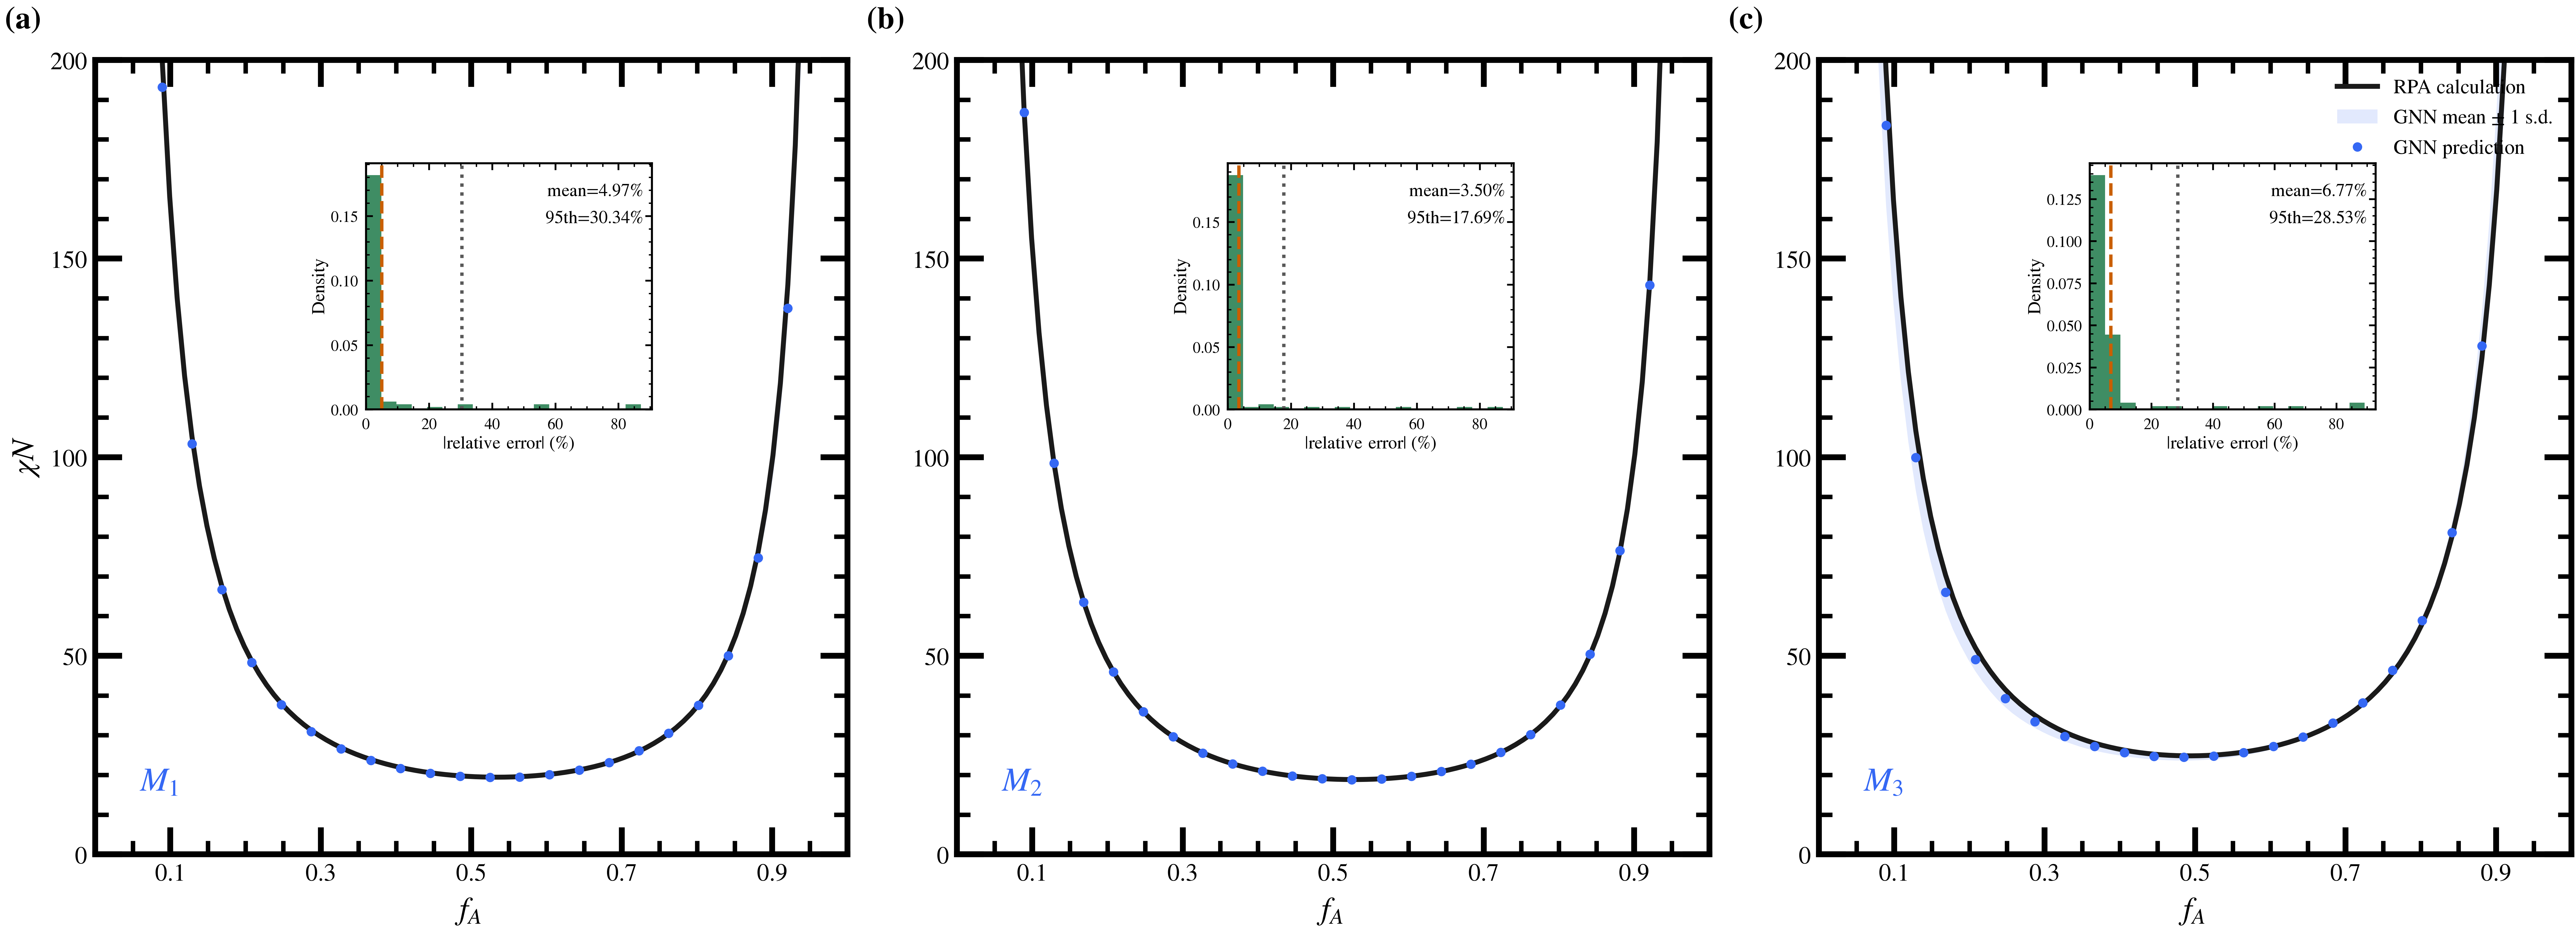

In [6]:
# Each inset summarizes all 100 composition points for one architecture.
with plt.rc_context({"font.size": 11, "axes.labelsize": 14,
                     "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 10}):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.8), constrained_layout=True)
    for column, (topology, case, label, _) in enumerate(CANDIDATE_TOPOLOGIES):
        values = candidate_data(topology, case)
        ax = axes[column]
        draw_candidate_curve(ax, values, label)
        ax.set_xlabel(r"$f_A$")
        if column:
            ax.set_ylabel("")
        ax.text(-0.12, 1.04, f"({chr(97 + column)})", transform=ax.transAxes,
                fontsize=14, fontweight="bold")

        ape = 100 * np.abs(values.ml_mean.to_numpy() - values.rpa_chiN.to_numpy()) / values.rpa_chiN.to_numpy()
        mean_error = float(ape.mean())
        p95 = float(np.percentile(ape, 95))
        inset = ax.inset_axes([0.36, 0.56, 0.38, 0.31])
        inset.hist(ape, bins=18, density=True, color=COLORS["density_green"],
                   alpha=0.86, edgecolor="none")
        inset.axvline(mean_error, color=COLORS["mean_orange"], ls="--", lw=1.5)
        inset.axvline(p95, color="0.35", ls=":", lw=1.5)
        inset.set_xlim(0, max(float(ape.max()) * 1.04, 10))
        inset.set_xlabel(r"$|\mathrm{relative\ error}|$ (%)", fontsize=8, labelpad=1)
        inset.set_ylabel("Density", fontsize=8, labelpad=1)
        inset.tick_params(axis="both", which="major", labelsize=7, length=3, width=0.8)
        inset.tick_params(axis="both", which="minor", length=1.5, width=0.6)
        for spine in inset.spines.values():
            spine.set_linewidth(0.9)
        inset.text(0.97, 0.94, f"mean={mean_error:.2f}%\n95th={p95:.2f}%",
                   transform=inset.transAxes, ha="right", va="top", fontsize=8)

    handles, labels = axes[-1].get_legend_handles_labels()
    axes[-1].legend(handles, labels, loc="upper right", frameon=False, fontsize=9)
    save_dual(fig, OUT / "figure10_candidate_error_distribution_insets")
    plt.close(fig)

display(Image(filename=str(OUT / "figure10_candidate_error_distribution_insets.png"), width=1200))
